In [2]:
# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
df = pd.read_csv("../data/processed/kyoto_real_estate_english.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (592, 17)


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 592 entries, 0 to 591
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   property_type             592 non-null    str    
 1   land_area_sqm             591 non-null    float64
 2   total_floor_area_sqm      569 non-null    float64
 3   year_built                487 non-null    float64
 4   station_distance_minutes  351 non-null    float64
 5   frontage_m                235 non-null    float64
 6   front_road_width_m        534 non-null    float64
 7   building_coverage_ratio   591 non-null    float64
 8   floor_area_ratio          591 non-null    float64
 9   building_structure        566 non-null    str    
 10  property_use              230 non-null    str    
 11  future_use                236 non-null    str    
 12  front_road_direction      496 non-null    str    
 13  front_road_type           497 non-null    str    
 14  city_planning        

In [7]:
# Check for missing values
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_table = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percent": missing_percent
})

missing_table = missing_table.sort_values(
    "missing_percent",
    ascending=False
)

missing_table

,missing_count,missing_percent
property_use,362,61.148649
frontage_m,357,60.304054
future_use,356,60.135135
station_distance_minutes,241,40.709459
year_built,105,17.736486
front_road_direction,96,16.216216
front_road_type,95,16.047297
front_road_width_m,58,9.797297
building_structure,26,4.391892
total_floor_area_sqm,23,3.885135


In [8]:
df["total_transaction_price"].describe()

count    5.920000e+02
mean     4.354527e+07
std      7.533917e+07
min      1.000000e+05
25%      1.700000e+07
50%      3.100000e+07
75%      4.525000e+07
max      1.400000e+09
Name: total_transaction_price, dtype: float64

In [9]:
print("Median price: ¥{:,.0f}".format(
    df["total_transaction_price"].median()
))

print("Mean price: ¥{:,.0f}".format(
    df["total_transaction_price"].mean()
))

print("Maximum price: ¥{:,.0f}".format(
    df["total_transaction_price"].max()
))

Median price: ¥31,000,000
Mean price: ¥43,545,270
Maximum price: ¥1,400,000,000


Image saved to:
C:\Users\Lenovo\ai_prjects\kyoto_house_price_prediction\backend\outputs\eda\01_price_distribution.png


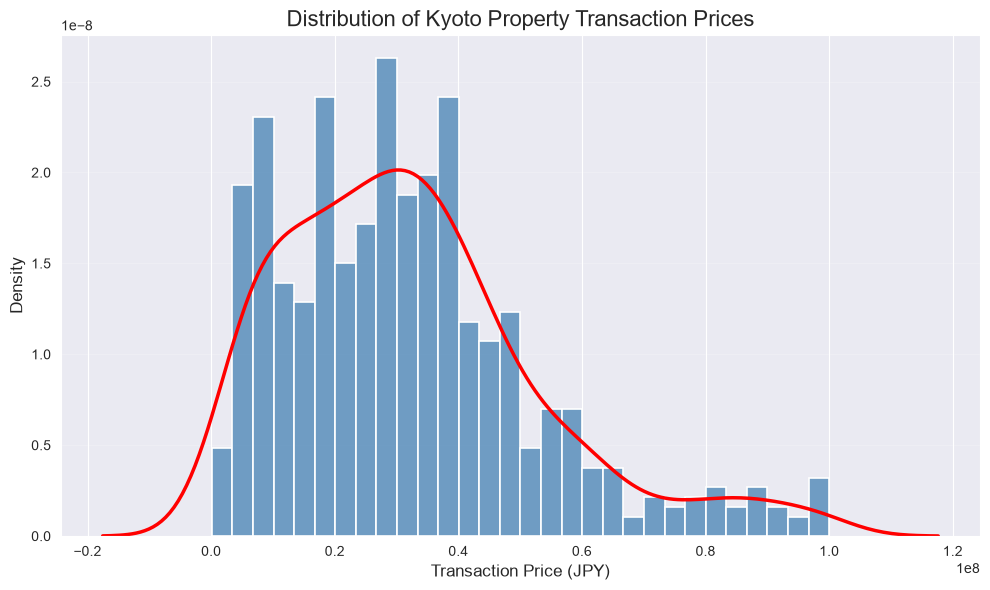

In [21]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

# Create EDA output folder
output_folder = Path("../outputs/eda")
output_folder.mkdir(parents=True, exist_ok=True)

# Price data up to ¥100 million
price_data = df[
    df["total_transaction_price"] <= 100_000_000
]["total_transaction_price"]

# Create figure
plt.figure(figsize=(10, 6))

# Histogram
sns.histplot(
    price_data,
    bins=30,
    color="steelblue",
    edgecolor="white",
    linewidth=1.2,
    stat="density"
)

# Red KDE curve
sns.kdeplot(
    price_data,
    color="red",
    linewidth=2.5
)

plt.title(
    "Distribution of Kyoto Property Transaction Prices",
    fontsize=16
)
plt.xlabel("Transaction Price (JPY)", fontsize=12)
plt.ylabel("Density", fontsize=12)

plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

# Save image
output_file = output_folder / "01_price_distribution.png"
plt.savefig(output_file, dpi=300, bbox_inches="tight")

print("Image saved to:")
print(output_file.resolve())

plt.show()

Image saved to:
C:\Users\Lenovo\ai_prjects\kyoto_house_price_prediction\backend\outputs\eda\02_log_price_distribution.png


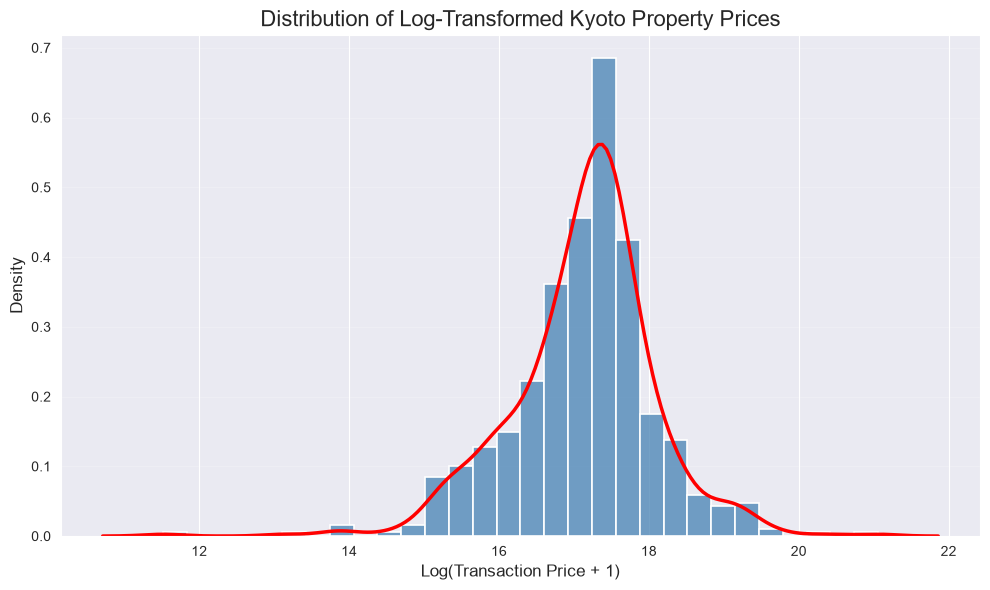

In [22]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Create output folder
output_folder = Path("../outputs/eda")
output_folder.mkdir(parents=True, exist_ok=True)

# Log-transform transaction price
log_price = np.log1p(df["total_transaction_price"])

plt.figure(figsize=(10, 6))

# Histogram
sns.histplot(
    log_price,
    bins=30,
    color="steelblue",
    edgecolor="white",
    linewidth=1.2,
    stat="density"
)

# KDE curve
sns.kdeplot(
    log_price,
    color="red",
    linewidth=2.5
)

plt.title(
    "Distribution of Log-Transformed Kyoto Property Prices",
    fontsize=16
)
plt.xlabel("Log(Transaction Price + 1)", fontsize=12)
plt.ylabel("Density", fontsize=12)

plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

# Save
output_file = output_folder / "02_log_price_distribution.png"
plt.savefig(output_file, dpi=300, bbox_inches="tight")

print("Image saved to:")
print(output_file.resolve())

plt.show()

Image saved to:
C:\Users\Lenovo\ai_prjects\kyoto_house_price_prediction\backend\outputs\eda\03_land_area_distribution.png


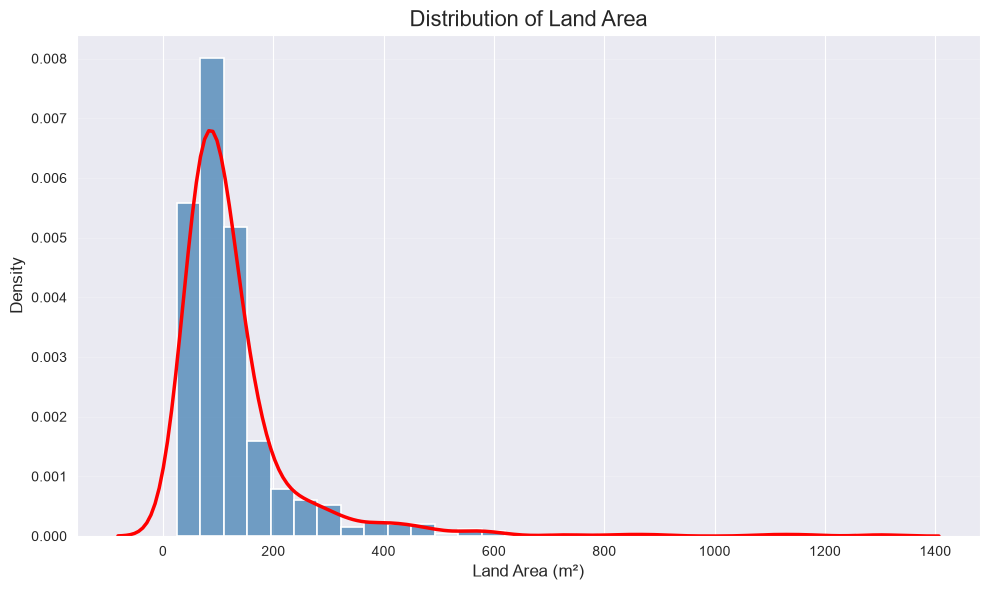

In [23]:
# land area
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

output_folder = Path("../outputs/eda")
output_folder.mkdir(parents=True, exist_ok=True)

area_data = df["land_area_sqm"].dropna()

plt.figure(figsize=(10, 6))

sns.histplot(
    area_data,
    bins=30,
    color="steelblue",
    edgecolor="white",
    linewidth=1.2,
    stat="density"
)

sns.kdeplot(
    area_data,
    color="red",
    linewidth=2.5
)

plt.title(
    "Distribution of Land Area",
    fontsize=16
)
plt.xlabel("Land Area (m²)", fontsize=12)
plt.ylabel("Density", fontsize=12)

plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

output_file = output_folder / "03_land_area_distribution.png"
plt.savefig(output_file, dpi=300, bbox_inches="tight")

print("Image saved to:")
print(output_file.resolve())

plt.show()